# Стационарное распределение температуры в прямоугольной квартире


**Постановка.** Температура каждой стены известна, внутри стационарный теплообмен без внутренних источников. Требуется построить разностную схему, получить **СЛАУ $A\mathbf t=\mathbf b$**, найти распределение температуры и исследовать решение.

В записанных конспектах нумерация стен различается. Мы следуем **первому рисунку**: $T_1$ — **слева**, $T_2$ — **сверху**, $T_3$ — **справа**, $T_4$ — **снизу**.

![Геометрия задачи](figures/geometry.png)

> Основной метод решения — собственная реализация **метода сопряжённых градиентов (CG)**, которая сравнивается с LU, Якоби, Зейдель, SOR и BiCGSTAB по точности. Также построена интерактивная 3D-модель. 

## 1. Уравнение и граничные условия

В стационарном режиме при постоянном коэффициенте теплопроводности $k$ и отсутствии источников из $\nabla\cdot(k\nabla T)=0$ получаем:

$$
\boxed{\frac{\partial^2T}{\partial x^2}+\frac{\partial^2T}{\partial y^2}=0}
$$

На $\Omega=(0,L_x)\times(0,L_y)$ заданы граничные условия:

$$
\begin{aligned}
T(0,y)&=T_1,\\
T(x,L_y)&=T_2,\\
T(L_x,y)&=T_3,\\
T(x,0)&=T_4.
\end{aligned}
$$

Четыре независимые постоянные температуры не могут одновременно выполняться **в углах**, если на соседних стенах разные значения. Внутреннее решение корректно; при рисовании в угловых точках берём **среднее двух прилегающих стен**.

Численный пример: размеры $6\times4$ м, $T_1=100$, $T_2=60$, $T_3=20$, $T_4=0\ ^\circ\mathrm C$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from dataclasses import dataclass
from time import perf_counter
from typing import Callable, Union
from scipy import sparse
from scipy.sparse.linalg import splu, bicgstab
from IPython.display import display, Markdown

np.set_printoptions(precision=3, suppress=True)
Profile = Union[float, Callable[[np.ndarray], np.ndarray]]


## 2. Геометрия сетки и запись температур на стенах

Пусть $n_x$ и $n_y$ — **число внутренних узлов**, без узлов на границе. Тогда

$$h_x=\frac{L_x}{n_x+1},\qquad h_y=\frac{L_y}{n_y+1}.$$

Неизвестных ровно $N=n_xn_y$. Индекс узла $(i,j)$ (при $i=0,\ldots,n_x-1$, $j=0,\ldots,n_y-1$) сворачиваем в индекс вектора $p=jn_x+i$: сначала проходим горизонтальную строку, затем переходим к следующей.

Для гибкости условия стен можно задавать и **числом**, и **функцией координаты**. Это пригодится при проверке точности на известном решении.

In [3]:
@dataclass(frozen=True)
class Rectangle:
    """Прямоугольник и ЧИСЛО ВНУТРЕННИХ узлов по x и y."""

    width: float = 6.0
    height: float = 4.0
    nx: int = 45
    ny: int = 30

    def __post_init__(self):
        if self.width <= 0 or self.height <= 0:
            raise ValueError("Размеры width и height должны быть положительными")
        if self.nx < 1 or self.ny < 1:
            raise ValueError("nx и ny должны быть >= 1")

    @property
    def hx(self):
        return self.width / (self.nx + 1)

    @property
    def hy(self):
        return self.height / (self.ny + 1)

    @property
    def x(self):
        return np.linspace(0, self.width, self.nx + 2)

    @property
    def y(self):
        return np.linspace(0, self.height, self.ny + 2)


@dataclass(frozen=True)
class Boundary:
    """Условия Дирихле: число (постоянная T) или функция координаты.

    left(y)   = T1; top(x)    = T2;
    right(y)  = T3; bottom(x) = T4.
    """

    left: Profile = 100.0
    top: Profile = 60.0
    right: Profile = 20.0
    bottom: Profile = 0.0


def _profile(value: Profile, coordinates: np.ndarray) -> np.ndarray:
    """Преобразовать число/функцию в массив температуры вдоль стены."""
    raw = value(coordinates) if callable(value) else value
    values = np.broadcast_to(np.asarray(raw, dtype=float), coordinates.shape).copy()
    if not np.all(np.isfinite(values)):
        raise ValueError("Граничные температуры должны быть конечными")
    return values


def boundary_values(grid: Rectangle, bc: Boundary) -> dict:
    """Все четыре массива граничных температур, включая углы."""
    return {
        "left": _profile(bc.left, grid.y),
        "top": _profile(bc.top, grid.x),
        "right": _profile(bc.right, grid.y),
        "bottom": _profile(bc.bottom, grid.x),
    }

## 3. Разностная схема и сборка СЛАУ

Разложение по Тейлору даёт центральную аппроксимацию второй производной:

$$\frac{\partial^2 T}{\partial x^2}\bigg|_{i,j}\approx
\frac{T_{i-1,j}-2T_{i,j}+T_{i+1,j}}{h_x^2}.$$

Для производной по $y$ аналогично. Подставив в $\Delta T=0$ и умножив на $-1$, получаем:

$$\boxed{\left(\frac2{h_x^2}+\frac2{h_y^2}\right)T_{i,j}
-\frac{T_{i-1,j}+T_{i+1,j}}{h_x^2}
-\frac{T_{i,j-1}+T_{i,j+1}}{h_y^2}=0.}$$

![Пятиточечный шаблон](figures/stencil.png)

**Как появляется правая часть?** Если сосед — известная стена, соответствующий член переносится направо с положительным знаком. Например, для узла у левой стены справа будет добавлено $T_1/h_x^2$; для узла у нижней стены — $T_4/h_y^2$.

Следовательно, $A\mathbf t=\mathbf b$: в $A$ коэффициенты при **неизвестных**, в $\mathbf b$ — вклад от стен. Ниже матрицу строим **разреженной**, используя кронекеровы произведения; это компактная запись того же пятиузлового шаблона.

In [4]:
def build_system(grid: Rectangle, bc: Boundary):
    nx, ny = grid.nx, grid.ny
    inv_hx2, inv_hy2 = 1.0 / grid.hx**2, 1.0 / grid.hy**2

    # Одномерные операторы -d²/dx² и -d²/dy².
    Ax = sparse.diags(
        [-inv_hx2 * np.ones(nx - 1), 2 * inv_hx2 * np.ones(nx),
         -inv_hx2 * np.ones(nx - 1)],
        [-1, 0, 1], format="csr",
    )
    Ay = sparse.diags(
        [-inv_hy2 * np.ones(ny - 1), 2 * inv_hy2 * np.ones(ny),
         -inv_hy2 * np.ones(ny - 1)],
        [-1, 0, 1], format="csr",
    )
    # Разделение двух координат: A = I_y (x) Ax + Ay (x) I_x.
    A = sparse.kron(sparse.eye(ny, format="csr"), Ax, format="csr")
    A += sparse.kron(Ay, sparse.eye(nx, format="csr"), format="csr")

    edges = boundary_values(grid, bc)
    rhs = np.zeros((ny, nx), dtype=float)
    rhs[:, 0] += edges["left"][1:-1] * inv_hx2
    rhs[:, -1] += edges["right"][1:-1] * inv_hx2
    rhs[0, :] += edges["bottom"][1:-1] * inv_hy2
    rhs[-1, :] += edges["top"][1:-1] * inv_hy2
    return A.tocsr(), rhs.ravel()


def full_temperature(grid: Rectangle, bc: Boundary, inside: np.ndarray) -> np.ndarray:
    edges = boundary_values(grid, bc)
    T = np.zeros((grid.ny + 2, grid.nx + 2))
    T[1:-1, 1:-1] = np.asarray(inside).reshape(grid.ny, grid.nx)
    T[:, 0] = edges["left"]
    T[:, -1] = edges["right"]
    T[0, :] = edges["bottom"]
    T[-1, :] = edges["top"]
    T[0, 0] = (edges["bottom"][0] + edges["left"][0]) / 2
    T[0, -1] = (edges["bottom"][-1] + edges["right"][0]) / 2
    T[-1, 0] = (edges["top"][0] + edges["left"][-1]) / 2
    T[-1, -1] = (edges["top"][-1] + edges["right"][-1]) / 2
    return T


def relative_residual(A, x, b) -> float:
    return float(np.linalg.norm(A @ x - b) / max(np.linalg.norm(b), 1.0))


@dataclass
class Result:
    solution: np.ndarray
    method: str
    iterations: int
    residuals: list
    seconds: float
    converged: bool

    @property
    def residual(self):
        return float(self.residuals[-1])

### Посмотрим на маленькую СЛАУ «вручную»

Выведем матрицу для сетки $n_x=3$, $n_y=2$; тогда $N=6$ неизвестных. В ней сразу видно, что в каждой строке не более пяти ненулевых элементов.

In [5]:
small_room = Rectangle(width=3, height=2, nx=3, ny=2)
small_walls = Boundary(left=100, top=60, right=20, bottom=0)
A_small, b_small = build_system(small_room, small_walls)
print('Размер A:', A_small.shape, '\n')
print('A =\n', A_small.toarray())
print('b =', b_small)
print('Число ненулевых элементов:', A_small.nnz)


Размер A: (6, 6) 

A =
 [[ 8.056 -1.778  0.    -2.25   0.     0.   ]
 [-1.778  8.056 -1.778  0.    -2.25   0.   ]
 [ 0.    -1.778  8.056  0.     0.    -2.25 ]
 [-2.25   0.     0.     8.056 -1.778  0.   ]
 [ 0.    -2.25   0.    -1.778  8.056 -1.778]
 [ 0.     0.    -2.25   0.    -1.778  8.056]]
b = [177.778   0.     35.556 312.778 135.    170.556]
Число ненулевых элементов: 20


## 4. Решаем систему **методом сопряжённых градиентов (CG)**

### От системы к задаче минимизации

В предыдущем разделе мы получили систему $A\mathbf t=\mathbf b$. Здесь $\mathbf t$ — вектор **неизвестных температур во внутренних узлах**, $A$ содержит коэффициенты разностной схемы, а $\mathbf b$ учитывает заданные температуры стен. Нужно найти такой вектор $\mathbf t$, при котором все уравнения системы выполняются.

Для этого можно рассмотреть вспомогательную квадратичную функцию

$$
F(\mathbf t)=\frac12\mathbf t^{\mathsf T}A\mathbf t-\mathbf b^{\mathsf T}\mathbf t.
$$

Она введена как удобный способ решения СЛАУ. Поскольку $A$ симметрична, её градиент равен

$$
\nabla F(\mathbf t)=A\mathbf t-\mathbf b.
$$

Поэтому в точке минимума $\nabla F=0$, то есть выполняется исходная система $A\mathbf t=\mathbf b$. Обратно, для нашей матрицы решение системы действительно является **единственным минимумом** $F$: матрица $A$ положительно определена, то есть $\mathbf v^{\mathsf T}A\mathbf v>0$ для любого ненулевого $\mathbf v$.

Почему это верно здесь? Коэффициенты связи двух соседних внутренних узлов одинаковы в обеих соответствующих строках, поэтому $A=A^{\mathsf T}$. Если мысленно продолжить произвольный вектор $\mathbf v$ нулевыми значениями на границе, то $\mathbf v^{\mathsf T}A\mathbf v$ превращается в сумму квадратов разностей значений в соседних узлах с положительными весами $1/h_x^2$ и $1/h_y^2$. Эта сумма положительна для любого ненулевого $\mathbf v$: сетка связана с нулевой границей. Именно симметрия и положительная определённость позволяют применять CG.

### Невязка и направление движения

Начинаем с приближения $\mathbf t_0=\mathbf 0$. Вектор

$$
\mathbf r_k=\mathbf b-A\mathbf t_k=-\nabla F(\mathbf t_k)
$$

называется **невязкой**. Он показывает, насколько текущие температуры не удовлетворяют уравнениям: у точного решения $\mathbf r=\mathbf0$. Одновременно $\mathbf r_k$ направлен против градиента, то есть в сторону убывания $F$.

Можно было бы каждый раз двигаться только по невязке. Однако метод CG выбирает направления $\mathbf p_k$ так, чтобы новое движение не отменяло улучшение, достигнутое вдоль предыдущих направлений. Такие направления называются **сопряжёнными относительно $A$**: для разных направлений $\mathbf p_i^{\mathsf T}A\mathbf p_j=0$. Это условие отличается от обычной перпендикулярности $\mathbf p_i^{\mathsf T}\mathbf p_j=0$.

### Откуда берутся формулы шага

1. **Начало.** Вычисляем $\mathbf r_0=\mathbf b-A\mathbf t_0$ и берём первое направление $\mathbf p_0=\mathbf r_0$. Если начальная невязка уже достаточно мала, решение найдено.

2. **Длина шага.** Ищем следующее приближение в виде $\mathbf t_{k+1}=\mathbf t_k+\alpha_k\mathbf p_k$. Выберем $\alpha_k$ так, чтобы $F$ была минимальна на этой прямой. Подстановка в $F$ и приравнивание производной по $\alpha$ к нулю дают

   $$
   \alpha_k=\frac{\mathbf r_k^{\mathsf T}\mathbf p_k}{\mathbf p_k^{\mathsf T}A\mathbf p_k}
   =\frac{\mathbf r_k^{\mathsf T}\mathbf r_k}{\mathbf p_k^{\mathsf T}A\mathbf p_k}.
   $$

   Второе равенство следует из свойств направлений и невязок CG в точной арифметике. Знаменатель положителен для ненулевого $\mathbf p_k$ благодаря положительной определённости $A$.

3. **Обновление температуры и невязки.** Сделав шаг, получаем

   $$
   \mathbf t_{k+1}=\mathbf t_k+\alpha_k\mathbf p_k,\qquad
   \mathbf r_{k+1}=\mathbf r_k-\alpha_k A\mathbf p_k.
   $$

   Формула невязки получается непосредственной подстановкой нового $\mathbf t_{k+1}$ в $\mathbf b-A\mathbf t_{k+1}$; повторно вычислять $A\mathbf t_{k+1}$ не требуется.

4. **Новое направление.** Добавляем к новой невязке часть предыдущего направления:

   $$
   \mathbf p_{k+1}=\mathbf r_{k+1}+\beta_k\mathbf p_k,\qquad
   \beta_k=\frac{\mathbf r_{k+1}^{\mathsf T}\mathbf r_{k+1}}{\mathbf r_k^{\mathsf T}\mathbf r_k}.
   $$

   Множитель $\beta_k$ выбирается из условия сопряжённости $\mathbf p_{k+1}^{\mathsf T}A\mathbf p_k=0$. Из этого условия сначала получается $\beta_k=-\mathbf r_{k+1}^{\mathsf T}A\mathbf p_k/(\mathbf p_k^{\mathsf T}A\mathbf p_k)$; свойства CG позволяют записать его как отношение квадратов норм невязок выше. Затем повторяем шаги 2–4.

Останавливаемся, когда нормированная невязка достаточно мала:

$$
\frac{\|\mathbf r_k\|_2}{\max(\|\mathbf b\|_2,1)}\leq\varepsilon.
$$

Здесь $\|\cdot\|_2$ — обычная евклидова длина вектора, а единица в знаменателе защищает от деления на ноль при $\mathbf b=\mathbf0$. Малая невязка означает, что система выполняется приближённо; она сама по себе не равна ошибке температур. Если заданный предел числа итераций исчерпан раньше, функция сообщает, что сходимость не достигнута.

В коде ниже `x`, `r`, `p`, `Ap`, `alpha` и `beta` соответствуют $\mathbf t_k$, $\mathbf r_k$, $\mathbf p_k$, $A\mathbf p_k$, $\alpha_k$ и $\beta_k$. Список `hist` хранит нормированную невязку после каждого шага. Разреженная матрица используется через умножение `A @ p`, поэтому хранить её как плотную не нужно.

In [6]:
def solve_cg(A, b, tol=1e-9, max_iter=None) -> Result:
    """Сопряжённые градиенты: собственная реализация для SPD-матриц.

    A из build_system симметрична и положительно определена.
    """
    A = A.tocsr()
    b = np.asarray(b, dtype=float)
    n = len(b)
    if max_iter is None:
        max_iter = max(n, 200)
    x = np.zeros(n)
    r = b - A @ x
    p = r.copy()
    rr = float(r @ r)
    scale = max(np.linalg.norm(b), 1.0)
    hist = [np.sqrt(rr) / scale]
    start = perf_counter()
    for k in range(1, max_iter + 1):
        if hist[-1] <= tol:
            return Result(x, "CG", k - 1, hist, perf_counter() - start, True)
        Ap = A @ p
        denom = float(p @ Ap)
        if denom <= 0 or not np.isfinite(denom):
            raise ArithmeticError("CG требует симметричную положительно определённую A")
        alpha = rr / denom
        x += alpha * p
        r -= alpha * Ap
        rr_new = float(r @ r)
        hist.append(np.sqrt(max(rr_new, 0)) / scale)
        if hist[-1] <= tol:
            return Result(x, "CG", k, hist, perf_counter() - start, True)
        beta = rr_new / rr
        p = r + beta * p
        rr = rr_new
    return Result(x, "CG", max_iter, hist, perf_counter() - start, False)

## 5. Дополнительные методы (для сравнения)

- **Якоби:** новые компоненты вычисляем только из предыдущего приближения.
- **Зейдель:** уже вычисленные новые компоненты используем на той же итерации.
- **SOR:** к шагу Зейделя добавляем множитель релаксации $\omega$; при $\omega=1$ получаем метод Зейделя.
- **LU:** разреженное LU-разложение `scipy.sparse.linalg.splu`, прямое решение для сверки.
- **BiCGSTAB:** метод для более общих, в том числе несимметричных, систем; здесь его использование необязательно.

Для Якоби: $t_i^{(k+1)}=(b_i-\sum_{j\neq i}a_{ij}t_j^{(k)})/a_{ii}$. Для SOR:

$$
 t_i^{(k+1)}=(1-\omega)t_i^{(k)}+
\frac{\omega}{a_{ii}}\left(b_i-\sum_{j<i}a_{ij}t_j^{(k+1)}-\sum_{j>i}a_{ij}t_j^{(k)}\right).
$$

In [7]:
def solve_jacobi(A, b, tol=1e-8, max_iter=15000) -> Result:
    """Якоби: все компоненты следующего шага считаются из старого x."""
    A = A.tocsr()
    diagonal = A.diagonal()
    rest = A - sparse.diags(diagonal, format="csr")
    x = np.zeros(len(b))
    hist = [relative_residual(A, x, b)]
    start = perf_counter()
    for k in range(1, max_iter + 1):
        if hist[-1] <= tol:
            return Result(x, "Якоби", k - 1, hist, perf_counter() - start, True)
        x = (b - rest @ x) / diagonal
        hist.append(relative_residual(A, x, b))
        if hist[-1] <= tol:
            return Result(x, "Якоби", k, hist, perf_counter() - start, True)
    return Result(x, "Якоби", max_iter, hist, perf_counter() - start, False)


def solve_sor(A, b, omega=1.7, tol=1e-8, max_iter=10000) -> Result:
    """SOR: Gauss--Seidel с релаксацией 0 < omega < 2.

    omega=1 -> обычный метод Гаусса--Зейделя.
    Новые значения x[0], ..., x[i-1] используются сразу.
    """
    A = A.tocsr()
    diagonal = A.diagonal()
    x = np.zeros(len(b))
    hist = [relative_residual(A, x, b)]
    start = perf_counter()
    for k in range(1, max_iter + 1):
        if hist[-1] <= tol:
            return Result(x, "Зейдель" if omega == 1 else "SOR", k-1, hist,
                          perf_counter() - start, True)
        for p in range(len(b)):
            a, z = A.indptr[p], A.indptr[p+1]
            # A[p, :] @ x содержит diagonal[p]*x[p]; удаляем его.
            off_diag = np.dot(A.data[a:z], x[A.indices[a:z]]) - diagonal[p] * x[p]
            x_new = (b[p] - off_diag) / diagonal[p]
            x[p] = (1 - omega) * x[p] + omega * x_new
        hist.append(relative_residual(A, x, b))
        if hist[-1] <= tol:
            return Result(x, "Зейдель" if omega == 1 else "SOR", k, hist,
                          perf_counter() - start, True)
    return Result(x, "Зейдель" if omega == 1 else "SOR", max_iter, hist,
                  perf_counter() - start, False)


def solve_lu(A, b) -> Result:
    """Прямой метод: разреженное LU-разложение (SuperLU в SciPy)."""
    start = perf_counter()
    factorization = splu(A.tocsc())
    x = factorization.solve(np.asarray(b, dtype=float))
    return Result(x, "LU", 0, [relative_residual(A, x, b)],
                  perf_counter() - start, True)


def solve_bicgstab(A, b, tol=1e-9, max_iter=None) -> Result:
    """BiCGSTAB из SciPy. Для этой SPD-задачи обычно проще CG."""
    if max_iter is None:
        max_iter = max(A.shape[0], 200)
    x0 = np.zeros_like(b, dtype=float)
    hist = [relative_residual(A, x0, b)]
    start = perf_counter()

    def callback(xk):
        hist.append(relative_residual(A, xk, b))

    x, status = bicgstab(A, b, x0=x0, rtol=tol, atol=0.0,
                        maxiter=max_iter, callback=callback)
    final_res = relative_residual(A, x, b)
    if abs(final_res - hist[-1]) > 1e-15:
        hist.append(final_res)
    return Result(x, "BiCGSTAB", len(hist)-1, hist,
                  perf_counter() - start, status == 0)


def solve(A, b, method="CG", tol=1e-9, omega=1.7, max_iter=None) -> Result:
    """Общий интерфейс выбора метода для ноутбука и тестов."""
    if method == "CG":
        return solve_cg(A, b, tol=tol, max_iter=max_iter)
    if method == "LU":
        return solve_lu(A, b)
    if method == "Якоби":
        return solve_jacobi(A, b, tol=tol,
                            max_iter=15000 if max_iter is None else max_iter)
    if method == "Зейдель":
        return solve_sor(A, b, omega=1, tol=tol,
                         max_iter=10000 if max_iter is None else max_iter)
    if method == "SOR":
        return solve_sor(A, b, omega=omega, tol=tol,
                         max_iter=10000 if max_iter is None else max_iter)
    if method == "BiCGSTAB":
        return solve_bicgstab(A, b, tol=tol, max_iter=max_iter)
    raise ValueError(f"Неизвестный метод: {method}")


def solve_temperature(grid: Rectangle, bc: Boundary, method="CG", **kwargs):
    """Вернуть (T_со_стенами, результат_метода, A, b)."""
    A, b = build_system(grid, bc)
    result = solve(A, b, method=method, **kwargs)
    return full_temperature(grid, bc, result.solution), result, A, b


def heat_flux(grid: Rectangle, temperature: np.ndarray):
    """q=-grad(T) (коэффициент теплопроводности k принят равным 1)."""
    dT_dy, dT_dx = np.gradient(temperature, grid.hy, grid.hx)
    return -dT_dx, -dT_dy

## 6. Получаем поле температуры

Введём желаемые параметры и найдём распределение $T(x_i,y_j)$ внутри. Функция `full_temperature` добавит значения на границе для визуализации.

In [8]:
room = Rectangle(width=6.0, height=4.0, nx=45, ny=30)
walls = Boundary(left=100, top=60, right=20, bottom=0)

T, result, A, b = solve_temperature(room, walls, method='CG', tol=1e-10)

print(f'Число неизвестных: {A.shape[0]}')
print(f'Ненулевых элементов A: {A.nnz}')
print(f'CG: {result.iterations} итераций')
print(f'Относительная невязка: {relative_residual(A, result.solution, b):.3e}')
print(f'T около центра: {T[(room.ny+1)//2, (room.nx+1)//2]:.2f} °C')
assert result.converged, 'Точность не достигнута: увеличьте max_iter.'
assert T[1:-1,1:-1].min() >= -1e-6
assert T[1:-1,1:-1].max() <= 100 + 1e-6


Число неизвестных: 1350
Ненулевых элементов A: 6600
CG: 145 итераций
Относительная невязка: 8.514e-11
T около центра: 36.22 °C


## 7. Графики: температурная карта, изотермы, тепловой поток

Изотермы показывают линии постоянной температуры. Тепловой поток вычисляем как $\mathbf q=-k\nabla T$. Здесь для иллюстрации принято $k=1$: интересуют направление и относительная величина (не абсолютный поток в Вт/м²).

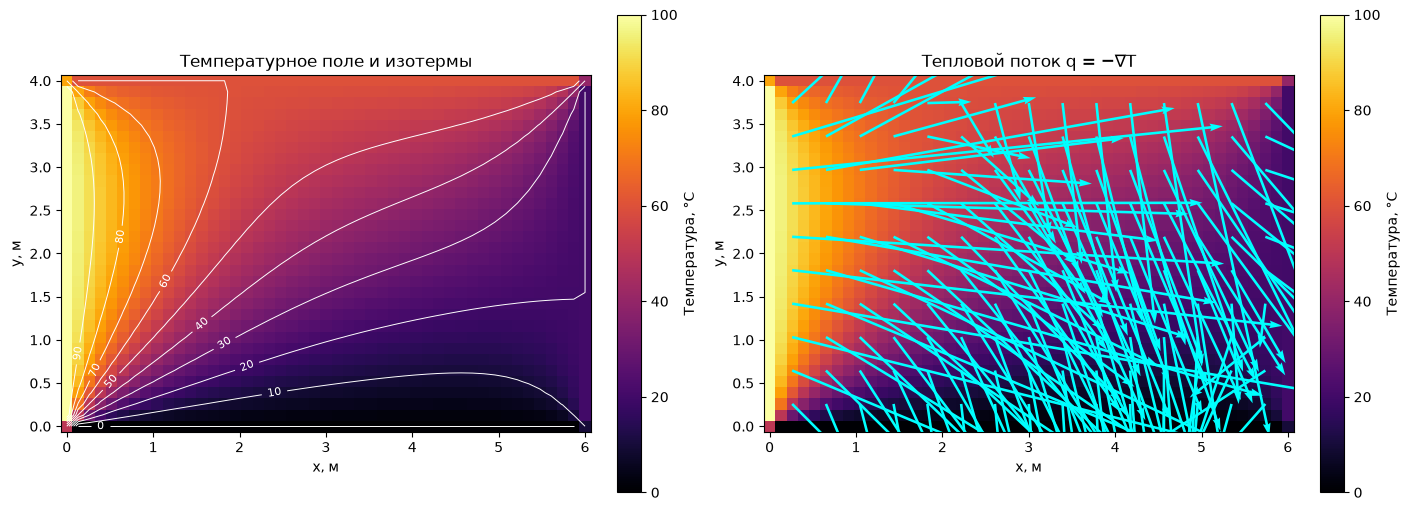

In [9]:
xx, yy = np.meshgrid(room.x, room.y)
qx, qy = heat_flux(room, T)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

plot1 = axes[0].pcolormesh(xx, yy, T, cmap='inferno', shading='auto')
lines = axes[0].contour(xx, yy, T, colors='white', levels=10, linewidths=0.7)
axes[0].clabel(lines, fontsize=8)
fig.colorbar(plot1, ax=axes[0], label='Температура, °C')
axes[0].set_title('Температурное поле и изотермы')

plot2 = axes[1].pcolormesh(xx, yy, T, cmap='inferno', shading='auto')
step = 3
axes[1].quiver(xx[2:-2:step, 2:-2:step], yy[2:-2:step, 2:-2:step],
               qx[2:-2:step, 2:-2:step], qy[2:-2:step, 2:-2:step],
               color='cyan', scale=40)
fig.colorbar(plot2, ax=axes[1], label='Температура, °C')
axes[1].set_title('Тепловой поток q = −∇T')
for ax in axes:
    ax.set_aspect('equal'); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
plt.show()


## 8. Plotly: интерактивная 2D-карта и вращаемая 3D-поверхность

На карте можно наводить курсор на точки, приближать области, менять масштаб; 3D-поверхность можно вращать мышью.

In [10]:
def plot_interactive(grid, temperature, title='Температура'):
    fig = make_subplots(rows=1, cols=2,
                        specs=[[{'type': 'xy'}, {'type': 'scene'}]],
                        subplot_titles=('2D: температура', '3D: поверхность T(x, y)'),
                        horizontal_spacing=0.08)
    fig.add_trace(go.Heatmap(x=grid.x, y=grid.y, z=temperature,
                             colorscale='Turbo',
                             hovertemplate='x=%{x:.2f} м<br>y=%{y:.2f} м<br>T=%{z:.2f} °C<extra></extra>',
                             colorbar=dict(title='°C', x=0.43)), row=1, col=1)
    fig.add_trace(go.Surface(x=grid.x, y=grid.y, z=temperature,
                             colorscale='Turbo', showscale=False,
                             hovertemplate='x=%{x:.2f} м<br>y=%{y:.2f} м<br>T=%{z:.2f} °C<extra></extra>'),
                  row=1, col=2)
    fig.update_xaxes(title='x, м', row=1, col=1)
    fig.update_yaxes(title='y, м', scaleanchor='x', scaleratio=1, row=1, col=1)
    fig.update_scenes(xaxis_title='x, м', yaxis_title='y, м', zaxis_title='°C',
                      aspectmode='manual', aspectratio=dict(x=1.5,y=1,z=0.9))
    fig.update_layout(title=title, height=530, width=1160,
                      margin=dict(l=40, r=20, b=15, t=85), template='plotly_white')
    return fig

plot_interactive(room, T).show()


## 9. Сравнение методов на одинаковой СЛАУ

На небольшой сетке $24\times16$ решим одну задачу шестью методами. Прямое LU-разложение используем как **контрольное численное решение**, а не как точную аналитическую функцию. Для итерационных методов используем одну и ту же относительную невязку $10^{-8}$.

Метод         Итераций       Невязка  Макс. отличие от LU
LU                   0      1.03e-15             0.00e+00
CG                  67      9.28e-09             1.02e-06
BiCGSTAB            51      9.08e-09             4.80e-06
SOR                 89      9.37e-09             6.41e-06
Зейдель            622      9.98e-09             9.81e-06
Якоби             1241      9.99e-09             9.87e-06


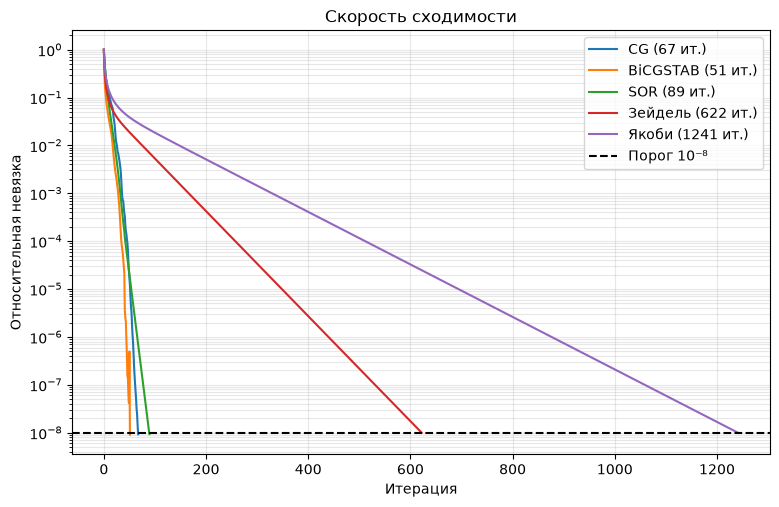

In [11]:
compare_room = Rectangle(width=6, height=4, nx=24, ny=16)
A_comp, b_comp = build_system(compare_room, walls)
method_names = ['LU', 'CG', 'BiCGSTAB', 'SOR', 'Зейдель', 'Якоби']
answers = {name: solve(A_comp, b_comp, method=name, tol=1e-8, omega=1.7,
                       max_iter=6000) for name in method_names}

ref_solution = answers['LU'].solution
print(f'{"Метод":<11} {"Итераций":>10} {"Невязка":>13} {"Макс. отличие от LU":>20}')
for name in method_names:
    r = answers[name]
    max_diff = np.max(np.abs(r.solution - ref_solution))
    print(f'{name:<11} {r.iterations:>10d} {r.residual:>13.2e} {max_diff:>20.2e}')
    assert r.converged

fig, ax = plt.subplots(figsize=(9,5.5))
for name in method_names[1:]:
    r = answers[name]
    ax.semilogy(range(len(r.residuals)), np.maximum(r.residuals, 1e-16),
                label=f'{name} ({r.iterations} ит.)')
ax.axhline(1e-8, ls='--', color='black', label='Порог 10⁻⁸')
ax.set(xlabel='Итерация', ylabel='Относительная невязка',
       title='Скорость сходимости')
ax.grid(True, which='both', alpha=0.3)
ax.legend(); plt.show()


## 10. Интерактивная визуализация с ползунками

Меняем температуры стен, размеры и разрешение сетки, метод решения и параметр $\omega$. При изменении параметров решение пересчитывается заново. Уточнение: **дольше всего** при больших сетках могут работать Якоби и Зейдель.

Если `ipywidgets` ещё не установлен, выполните отдельной ячейкой `%pip install ipywidgets` и перезапустите kernel. **Альтернатива без установок:** откройте соседний файл `interactive_apartment.html` — это самодостаточная интерактивная страница с решателем SOR, который работает прямо в браузере.


In [12]:
try:
    import ipywidgets as widgets
except ImportError:
    print('Для ползунков установите ipywidgets: %pip install ipywidgets')
    print('Или откройте interactive_apartment.html в браузере.')
else:
    controls = {
        'T1': widgets.FloatSlider(value=100, min=-50, max=150, step=5,
                                  description='T₁ слева', continuous_update=False),
        'T2': widgets.FloatSlider(value=60, min=-50, max=150, step=5,
                                  description='T₂ сверху', continuous_update=False),
        'T3': widgets.FloatSlider(value=20, min=-50, max=150, step=5,
                                  description='T₃ справа', continuous_update=False),
        'T4': widgets.FloatSlider(value=0, min=-50, max=150, step=5,
                                  description='T₄ снизу', continuous_update=False),
        'Lx': widgets.FloatSlider(value=6, min=2, max=12, step=0.5,
                                  description='Ширина', continuous_update=False),
        'Ly': widgets.FloatSlider(value=4, min=2, max=10, step=0.5,
                                  description='Высота', continuous_update=False),
        'nx': widgets.IntSlider(value=30, min=5, max=65, step=5,
                                 description='Узлов по x', continuous_update=False),
        'ny': widgets.IntSlider(value=20, min=5, max=55, step=5,
                                 description='Узлов по y', continuous_update=False),
        'method': widgets.Dropdown(options=['CG', 'LU', 'SOR', 'Зейдель', 'Якоби', 'BiCGSTAB'],
                                   value='CG', description='Метод'),
        'omega': widgets.FloatSlider(value=1.7, min=1.0, max=1.95, step=0.05,
                                     description='ω (SOR)', continuous_update=False),
    }

    def recompute(T1, T2, T3, T4, Lx, Ly, nx, ny, method, omega):
        local_grid = Rectangle(width=Lx, height=Ly, nx=nx, ny=ny)
        local_bc = Boundary(left=T1, top=T2, right=T3, bottom=T4)
        field, result, mat, rhs = solve_temperature(
            local_grid, local_bc, method=method, tol=1e-8,
            omega=omega, max_iter=6000)
        print(f'{method}: {result.iterations} итераций; '
              f'невязка = {relative_residual(mat, result.solution, rhs):.2e}; '
              f'{"сошёлся" if result.converged else "лимит итераций!"}')
        plot_interactive(local_grid, field, title=f'{method}: T(x, y)').show()

    panel = widgets.VBox([
        widgets.HTML('<h3>Условия на стенах</h3>'),
        widgets.HBox([widgets.VBox([controls['T1'], controls['T2']]),
                      widgets.VBox([controls['T3'], controls['T4']])]),
        widgets.HTML('<h3>Сетка и метод</h3>'),
        widgets.HBox([widgets.VBox([controls['Lx'], controls['Ly'], controls['nx'], controls['ny']]),
                      widgets.VBox([controls['method'], controls['omega']])]),
    ])
    display(panel, widgets.interactive_output(recompute, controls))


Output()

## 11. Выводы

1. Метод конечных разностей превратил стационарную задачу теплопроводности в **разреженную СЛАУ** с $N=n_xn_y$ неизвестными и не более чем пятью ненулевыми коэффициентами в строке.
2. Выбор $A=-\Delta_h$ дал **симметричную положительно определённую матрицу**, поэтому основной метод **CG** обоснован математически.
3. Результат проверяется независимо: сравнением с разреженным **LU**, тестом постоянной температуры и экспериментальным подтверждением **второго порядка точности** на известной гармонической функции.
4. Точность СЛАУ (малая невязка) **не равна** точности аппроксимации дифференциального уравнения: последняя улучшается при измельчении сетки.
5. Если необходимо моделировать **изменение температуры со временем**, потребуется решать $\partial_t T=\alpha\Delta T$ и добавить начальные условия; данный проект описывает только **стационарный режим**.

